# [GSE210504](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE210504)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2024-09-17
> - Modified: 2024-09-17

# 1. Experimental Design

> N-acetyltransferase NAT10 Controls Cell Fates via RNA Cytidine Acetylation.
> - Zhensheng Hu et al. ,N-acetyltransferase NAT10 controls cell fates via connecting mRNA cytidine acetylation to chromatin signaling.Sci. Adv.10,eadh9871(2024).DOI:10.1126/sciadv.adh9871.
> - acRIP-seq (Abcam, anti-ac4C antibody)
> - SMARTer Stranded Total RNA-Seq Kit v2 (Takara)
> - Illumina NovaSeq 6000, PE150
> - mm10

| Sample | Organism | Cell | Source | Strain | Genotype | Antibody | Replicate |
| - | - | - | - | - | - | - | - |
| Ctrl | Homo sapiens | hESC | Embryionic stem cell | MEL1 | Control | ac4C | rep1~2 |
| shNAT10 | Homo sapiens | hESC | Embryionic stem cell | MEL1 | shNAT10 | ac4C | rep1~2 |

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(rtracklayer))
suppressPackageStartupMessages(library(GenomicRanges))
suppressPackageStartupMessages(library(GenomeInfoDb))
suppressPackageStartupMessages(library(EnrichedHeatmap))
suppressPackageStartupMessages(library(RColorBrewer))
suppressPackageStartupMessages(library(viridis))
suppressPackageStartupMessages(library(cowplot))
suppressPackageStartupMessages(library(ggpubr))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_1/bulk_omics/ac4cripseq_Hs_ESC_NAT10_GSE210504/02_output"

gtf_file <- "~/reference/Homo_sapiens/hg38/gencode.v48.annotation.gtf"

suppressPackageStartupMessages(library(BSgenome.Hsapiens.UCSC.hg38))
genome <- BSgenome.Hsapiens.UCSC.hg38

In [17]:
# load reference gene anntotion
gtf <- import(gtf_file) |>
    BRGenomics::tidyChromosomes(keep.X = TRUE, keep.Y = TRUE, keep.M = FALSE)

txdb <- txdbmaker::makeTxDbFromGRanges(
    gtf, drop.stop.codons = TRUE, taxonomyId = 10090, 
    metadata = data.frame(
        name = c("Genome", "Gencode Release"),
        value = c("mm10", "vM23")))

Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
"The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored."
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
"genome version information is not available for this TxDb object"


# 2. Data Import

## 1). narrowPeak Import

In [3]:
source("~/biology_knowledge_base/06_analysis/00_script/r/01_data_import/load_peaks.R")

In [5]:
peaks_files <- file.path(data_dir, "05_peaks") |>
    list.files(pattern = "_ac4C_peaks\\.narrowPeak$", full.names = TRUE) |>
    set_names(~ sub(
        "hESC_(.*)_ac4C_peaks\\.narrowPeak$", "\\1", basename(.x)))

paste(names(peaks_files), basename(peaks_files), sep = ": ") |> 
    cat(sep = "\n")

Ctrl_rep1: hESC_Ctrl_rep1_ac4C_peaks.narrowPeak
Ctrl_rep2: hESC_Ctrl_rep2_ac4C_peaks.narrowPeak
shNAT10_rep1: hESC_shNAT10_rep1_ac4C_peaks.narrowPeak
shNAT10_rep2: hESC_shNAT10_rep2_ac4C_peaks.narrowPeak


In [6]:
peaks_list <- lapply(
    peaks_files, load_peaks, dropSex = FALSE, verbose = FALSE)

peaks_list[1]

$Ctrl_rep1
GRanges object with 6457 ranges and 6 metadata columns:
         seqnames            ranges strand |                   name     score
            <Rle>         <IRanges>  <Rle> |            <character> <numeric>
     [1]     chr1     789922-790072      + | hESC_Ctrl_rep1_ac4C_..       114
     [2]     chr1     792288-792437      + | hESC_Ctrl_rep1_ac4C_..        66
     [3]     chr1     792820-792972      + | hESC_Ctrl_rep1_ac4C_..       117
     [4]     chr1   1312895-1313079      + | hESC_Ctrl_rep1_ac4C_..       846
     [5]     chr1   1387855-1388150      + | hESC_Ctrl_rep1_ac4C_..        63
     ...      ...               ...    ... .                    ...       ...
  [6453]     chrY 56830752-56831108      - | hESC_Ctrl_rep1_ac4C_..        79
  [6454]     chrY 56832695-56832844      - | hESC_Ctrl_rep1_ac4C_..        78
  [6455]     chrY 56834993-56835289      - | hESC_Ctrl_rep1_ac4C_..       181
  [6456]     chrY 56836637-56836786      - | hESC_Ctrl_rep1_ac4C_..        

In [13]:
coldata <- data.frame(sample = names(peaks_list)) |>
    separate(
        sample, into = c("Group", "Replicate"), sep = "_", remove = FALSE) |>
    mutate(
        Group = factor(Group, levels = c("Ctrl", "shNAT10")), 
        Replicate = factor(Replicate)) |>
    arrange(Group, Replicate) |>
    column_to_rownames("sample")

coldata

,Group,Replicate
,<fct>,<fct>
Ctrl_rep1,Ctrl,rep1
Ctrl_rep2,Ctrl,rep2
shNAT10_rep1,shNAT10,rep1
shNAT10_rep2,shNAT10,rep2


# 3. Evaluate Library Quality

## 1). Mapping Statistics

| Sample Name | Raw Reads (M) | Clean Reads (M) | Mapped Reads (M) | Mapping Rate | Duplication Rate | Filter Mapped Reads (M) | Filter Mapping Rate | Fragment Length | Number of Peaks | FRIP |
| - | - | - | - | - | - | - | - | - | - | - |
| - | - | - | - | - | - | - | - | - | - | - |

## 2). Number of Peaks

In [14]:
plot_df <- data.frame(sample = names(peaks_list)) |>
    separate(
        sample, into = c("Group", "Replicate"), sep = "_", remove = FALSE) |>
    mutate(
        Group = factor(Group, levels = c("Ctrl", "shNAT10")), 
        Replicate = factor(Replicate), 
        number = lengths(peaks_list)) |>
    arrange(Group, Replicate) |> 
    column_to_rownames("sample")

plot_df

,Group,Replicate,number
,<fct>,<fct>,<int>
Ctrl_rep1,Ctrl,rep1,6457
Ctrl_rep2,Ctrl,rep2,5233
shNAT10_rep1,shNAT10,rep1,5223
shNAT10_rep2,shNAT10,rep2,4247


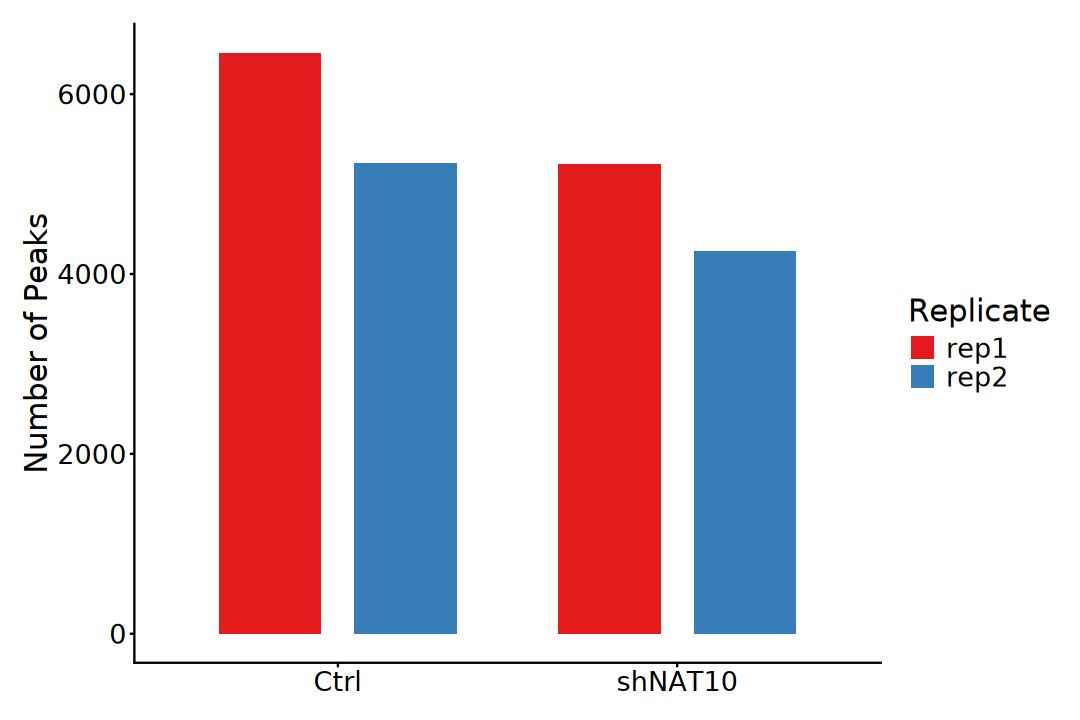

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = number, group = Replicate)) +
    geom_bar(
        aes(fill = Replicate), stat = "identity", 
        position = position_dodge(width = 0.8), 
        width = 0.6, linewidth = 1.5) +
    scale_fill_brewer(palette = "Set1") +
    labs(x = NULL, y = "Number of Peaks") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 3). Replicate Consistency

In [12]:
# ------------------------------------------------------------------------------
# Function: summarize_peak_overlaps
#
# Description:
# Summarize the overlap composition of peak sets across replicates.
#
# Arguments:
#   peaks_list : named list of GRanges.
#   peaks      : short names used for display and ordering.
#                Default: rep1, rep2, ..., repN.
# ------------------------------------------------------------------------------
summarize_peak_overlaps <- function(
    peaks_list, peaks = paste0("rep", seq_along(peaks_list))) {

    names(peaks_list) <- peaks

    comb_levels <- unlist(
        lapply(seq_along(peaks), function(i) {
            combn(peaks, i, FUN = paste, collapse = "&")
        }), use.names = FALSE)

    ol <- lapply(peaks_list, function(gr) {
            names(gr) <- gr$name
            return(gr)
        }) |>
            ChIPpeakAnno::findOverlapsOfPeaks()

    ol$venn_cnt[, c(names(peaks_list), "Counts"), drop = FALSE] |>
        as.data.frame(stringsAsFactors = FALSE) |>
        dplyr::rename_with(~ peaks, .cols = names(peaks_list)) |>
        dplyr::rowwise() |>
        dplyr::mutate(
            Combination = {
                present <- peaks[c_across(dplyr::all_of(peaks)) == 1]
                if (length(present) == 0) {
                    NA_character_
                } else {
                    paste(present, collapse = "&")
                }
            }
        ) |>
        dplyr::ungroup() |>
        dplyr::mutate(
            Combination = factor(Combination, levels = comb_levels)) |>
        dplyr::filter(!is.na(Combination)) |>
        dplyr::select(Combination, Counts) |>
        as.data.frame()
}

In [15]:
replicate_peak_df <- dplyr::bind_rows(
    Ctrl = summarize_peak_overlaps(
        peaks_list[coldata |> dplyr::filter(Group == "Ctrl") |> rownames()]
    ),
    shNAT10 = summarize_peak_overlaps(
        peaks_list[coldata |> dplyr::filter(Group == "shNAT10") |> rownames()]
    ),
    .id = "Group"
)

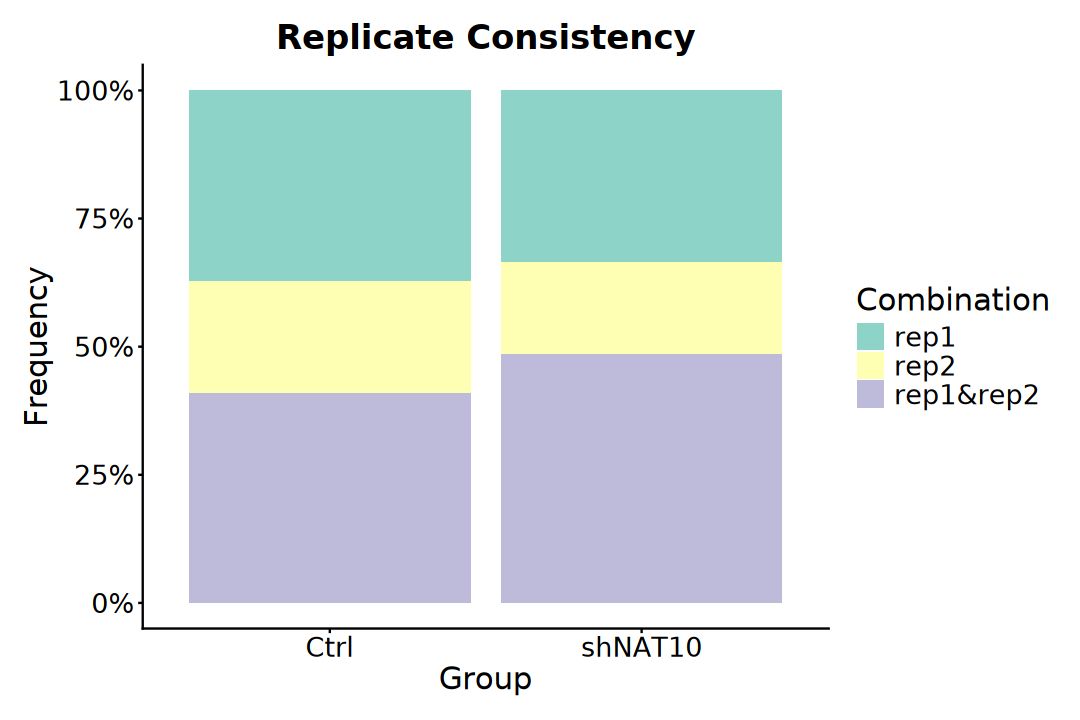

In [16]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(replicate_peak_df, aes(x = Group, y = Counts)) +
    geom_bar(aes(fill = Combination), stat = "identity", position = "fill") +
    scale_y_continuous(labels = scales::percent_format()) + 
    scale_fill_brewer(palette = "Set3") +
    labs(title = "Replicate Consistency", x = "Group", y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right", 
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 4). Guitar Plot

In [18]:
suppressPackageStartupMessages(library(Guitar))

In [19]:
guitarTxdb <- makeGuitarTxdb(
    txdb, txpromoterLength = 0, txtailLength = 0,
    pltTxType =  "mrna", withTxContext = TRUE)

[1] "There are 385632 transcripts of 78649 genes in the genome."
[1] "total 385632 transcripts extracted ..."
[1] "total 126108 transcripts left after ambiguity filter ..."
[1] "total 126108 transcripts left after check chromosome validity ..."
[1] "total 10856 mRNAs left after component length filter ..."
[1] "total 91007 ncRNAs left after ncRNA length filter ..."
[1] "generate components for mRNA"
[1] "generate chiped transcriptome"
[1] "generate coverage checking ranges for mrna"


In [20]:
str(guitarTxdb$mrna$componentWidthAverage_pct)

 Named num [1:5] 0 0.132 0.434 0.434 0
 - attr(*, "names")= chr [1:5] "promoter" "utr5" "cds" "utr3" ...


In [21]:
txMrnaComponentProp <- guitarTxdb$mrna$componentWidthAverage_pct

In [24]:
plot_guitar_dat <- GuitarPlot(
    txTxdb = txdb, 
    stGRangeLists = peaks_list, 
    headOrtail = FALSE, 
    enableCI = FALSE, 
    mapFilterTranscript = TRUE, 
    pltTxType = "mrna", 
    stGroupName = names(peaks_list)
)

[1] "20260909170242"
[1] "There are 385632 transcripts of 78649 genes in the genome."
[1] "total 385632 transcripts extracted ..."
[1] "total 126108 transcripts left after ambiguity filter ..."
[1] "total 126108 transcripts left after check chromosome validity ..."
[1] "total 10856 mRNAs left after component length filter ..."
[1] "total 91007 ncRNAs left after ncRNA length filter ..."
[1] "generate components for mRNA"
[1] "generate chiped transcriptome"
[1] "generate coverage checking ranges for mrna"
[1] "20260909170616"
[1] "sample 10 points for Ctrl_rep1"
[1] "sample 10 points for Ctrl_rep2"
[1] "sample 10 points for shNAT10_rep1"
[1] "sample 10 points for shNAT10_rep2"
[1] "start figure plotting for mrna ..."


Warning message:
"Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the Guitar package.
  Please report the issue to the authors."


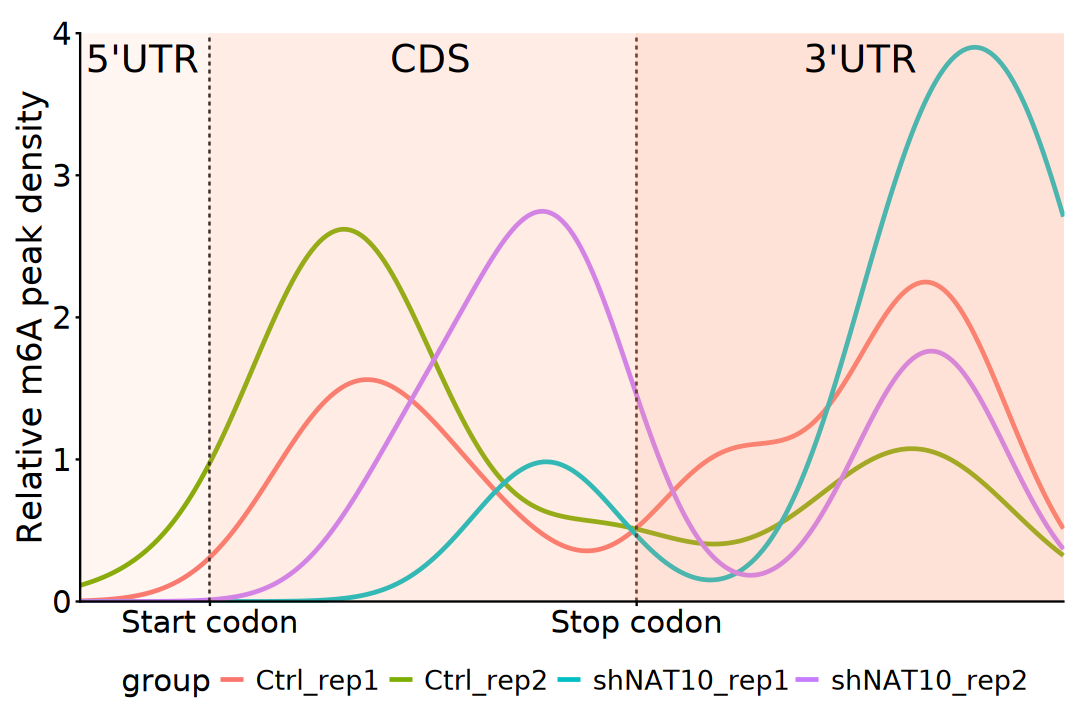

In [32]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggplot(plot_guitar_dat$data, aes(x = x, y = density, colour = group)) +
    geom_line(alpha = 1, linewidth = 1) +
    geom_vline(aes(xintercept = sum(txMrnaComponentProp[1:2])), linetype = "dashed") + 
    geom_vline(aes(xintercept = sum(txMrnaComponentProp[1:3])), linetype = "dashed") + 
    annotate(
        "rect", xmin = 0, xmax = sum(txMrnaComponentProp[1:2]), 
        ymin = 0, ymax = 4, fill = "LightSalmon", alpha = 0.1) +
    annotate(
        "rect", xmin = sum(txMrnaComponentProp[1:2]), 
        xmax = sum(txMrnaComponentProp[1:3]), 
        ymin = 0, ymax = 4, fill = "LightSalmon", alpha = 0.2) +
    annotate(
        "rect", xmin = sum(txMrnaComponentProp[1:3]), xmax = 1, 
        ymin = 0, ymax = 4, fill = "LightSalmon", alpha = 0.3) +
    annotate("text", x = 0.063, y = 4, label = "5'UTR", vjust = 1.4, size = 8) +
    annotate("text", x = 0.356, y = 4, label = "CDS", vjust = 1.4, size = 8) +
    annotate("text", x = 0.793, y = 4, label = "3'UTR", vjust = 1.4, size = 8) +
    scale_x_continuous(
        breaks = c(sum(txMrnaComponentProp[1:2]), sum(txMrnaComponentProp[1:3])), 
        labels = c("Start codon", "Stop codon"), expand = c(0, 0)) +
    scale_y_continuous(expand = c(0, 0)) +
    labs(y = "Relative m6A peak density") + 
    theme_classic() +
    theme(
        plot.margin = margin(20, 10, 10, 10, "points"),
        legend.position = "bottom",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title.x = element_blank(),
        axis.title.y = element_text(size = 20),
        axis.text.y = element_text(size = 18),
        axis.text.x = element_text(size = 18))